# Real hardware

**Part 3 of 3: Hardware** · [← Part 2: Noise](02_noise.ipynb) · [README](../README.md)

**Question.** Does the detector find wins on a real quantum computer, and how
far is the hardware from the simulations of Part 2?

Every job in `results/` that ran on a real device is read back here: a summary
first, then what was sent, the noise measured in each job, all boards, and the
findings. Each job holds 20 calibration circuits next to its boards (Part 2,
section 3; 18 in jobs sent before the double-win calibration boards were
added, which then cannot measure how double wins differ). The notebook reads only saved records; no IBM account is needed.
Sending a new job is covered in the appendix.
Terms such as ε, cutoff and readout matrix are in the
[glossary of Part 1](01_how_it_works.ipynb#Glossary).

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

from qttt import plots
from qttt.analysis import OUTCOMES, describe, examples, jobs, outcome, rescore, summarize, wrong_winners
from qttt.results import RunStore
from qttt.stats import wilson_interval

STORE = RunStore("../results")
HARDWARE_ONLY = True  # False also shows simulated jobs saved in STORE (the tests use this)

## Summary

The share of wins found comes with a 95% *Wilson interval*: the range the true
rate plausibly lies in, given how many boards were run.

**612 boards on ibm_fez, ibm_kingston, ibm_marrakesh, in 3 jobs, error suppression off. No reported winner was wrong:** every flagged line is verified on the board.

| job | wins found | 95% interval | boards without a winner | false flags |
| :--- | ---: | ---: | ---: | ---: |
| ibm_marrakesh 2026-11-16 | 22 of 32 | 51%–82% | 16 | 0 |
| ibm_kingston 2026-11-16 | 163 of 163 | 98%–100% | 119 | 2 |
| ibm_fez 2026-11-16 | 21 of 163 | 9%–19% | 119 | 0 |

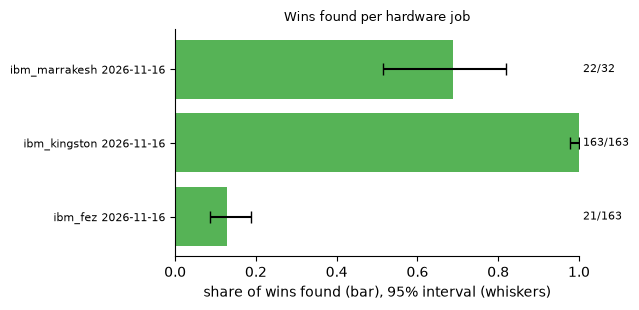

In [2]:
saved = [rescore(job) for job in jobs(STORE, hardware_only=HARDWARE_ONLY)]
if not saved:
    print(f"No hardware results saved yet in {STORE.root}; simulated runs are in 02_noise.")
else:
    detections = [d for job in saved for d in job.detections]
    assert not wrong_winners(detections)
    devices = ", ".join(sorted({job.backend["name"] for job in saved}))
    suppression = {job.suppression for job in saved}
    suppression = (f"error suppression {suppression.pop()}" if len(suppression) == 1
                   else "error suppression differs between jobs (section 1)")
    # One row per job: devices differ too much for a pooled rate to describe any of them.
    display(plots.markdown(
        f"**{len(detections)} boards on {devices}, in {len(saved)} job{'s' if len(saved) > 1 else ''}, "
        f"{suppression}. No reported winner was wrong:** every flagged line is verified on the board."))
    summary = []
    for job in saved:
        with_winner = [d for d in job.detections if d["true_lines"]]
        no_winner = [d for d in job.detections if not d["true_lines"]]
        found = sum(bool(d["lines"]) for d in with_winner)
        low, high = wilson_interval(found, len(with_winner))
        summary.append((job.label, f"{found} of {len(with_winner)}", f"{low:.0%}–{high:.0%}", len(no_winner),
                        sum(len(d["rejected"]) for d in no_winner)))
    display(plots.table(["job", "wins found", "95% interval", "boards without a winner", "false flags"],
                        summary, "lrrrr"))
    rows = [(job.label, sum(bool(d["lines"]) for d in job.detections if d["true_lines"]),
             sum(bool(d["true_lines"]) for d in job.detections)) for job in saved]
    plots.found_by_job(rows, "Wins found per hardware job")
    plt.show()

## Example boards

A typical board of each kind (single win, double win, no win) and each outcome
the detector had, chosen as the median of its group by how clearly it was
scored. Each is drawn twice: on the left, the board with the hardware's output
on it, every line as thick as its share of the shots and its index in bold
once it reached its cutoff; on the right, the same shares as bars. On a
perfect device a single winning line carries about 78% of the shots
([Part 1, section 8](01_how_it_works.ipynb)), and each losing line about 12.5%
by chance.

**Reading the bars:** green is a real winning line, gray a losing one. Orange,
hatched and marked x: a losing line that reached its cutoff, so it was flagged
and then rejected by the classical check. The black tick on each bar is that
line's cutoff (from the noise profile measured in the job), and the dotted
line is 1/8, an even spread over all 8 lines. The line indices:

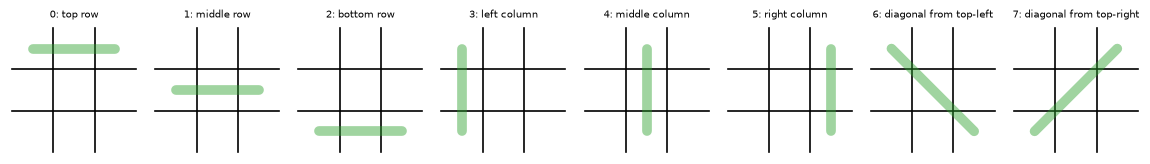

In [3]:
plots.line_key(bits=False)
plt.show()

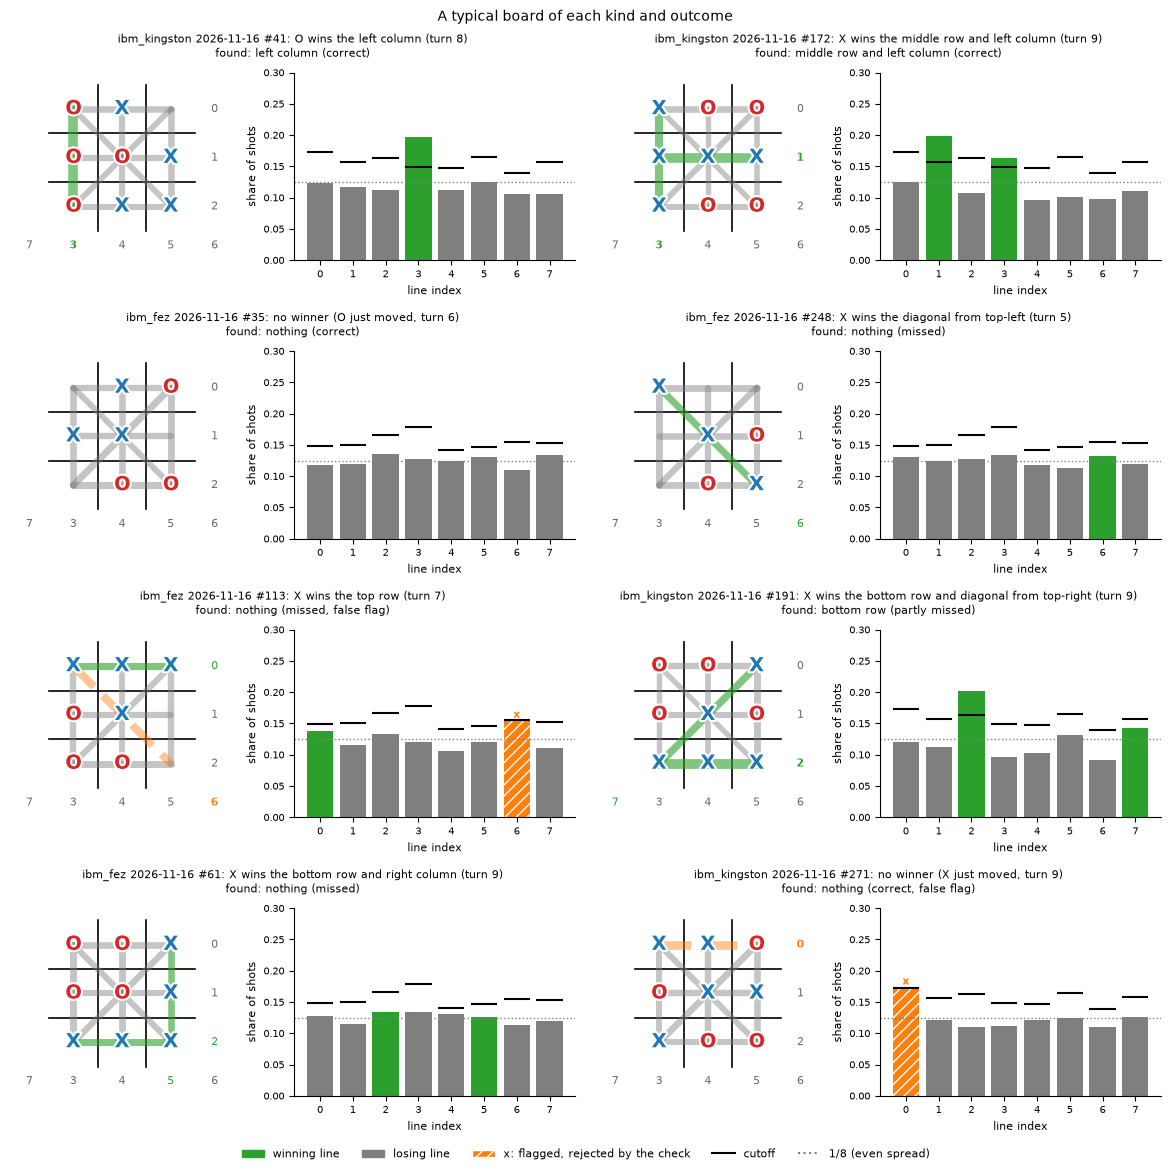

In [4]:
EXAMPLES = 8

entries = [(job.label, n, r) for job in saved for n, r in enumerate(job.detections, start=1)]
if entries:
    plots.board_details(examples(entries, EXAMPLES), "A typical board of each kind and outcome")
    plt.show()

## 1. Saved jobs

One line per job, oldest first: the device's own calibration date, the
compiled circuit and the error-suppression options it ran with.

<details><summary>How the verdicts are computed</summary>

Every verdict is recomputed from the job's saved counts
(`qttt.analysis.rescore`), so all jobs are scored with the current calibration
rule. The verdicts decided at run time remain in the saved records.
</details>

In [5]:
listing = []
for job in saved:
    b, m = job.backend, job.first["metrics"]
    changed = sum(d["lines"] != d["lines_at_run"] for d in job.detections)
    listing.append(
        f"- **{job.label}**: tag `{job.first['tag']}`, job `{job.first['job_id']}`, {len(job.detections)} boards, "
        f"{job.first['shots']} shots, device calibration data from {b['calibration_date'] or 'unpublished'}. "
        f"Circuit: {m['two_qubit_gates']} two-qubit gates, depth {m['depth']}, line qubits {m['line_qubits']}, "
        f"ancilla {'yes' if m.get('ancilla') else 'no'}; error suppression: {job.suppression}."
        + (f" Re-scored with the current calibration rule: {changed} board(s) differ from the verdict at run time."
           if changed else ""))
if saved:
    display(plots.markdown("\n".join(listing)))

- **ibm_marrakesh 2026-11-16**: tag `marrakesh-2`, job `dbt585req3sc73evdbp0`, 48 boards, 2048 shots, device calibration data from 2026-11-13T12:22:56-05:00. Circuit: 431 two-qubit gates, depth 1079, line qubits [53, 54, 39], ancilla yes; error suppression: off.
- **ibm_kingston 2026-11-16**: tag `kingston-1`, job `dbsvu3nasvbs73b95d10`, 282 boards, 2048 shots, device calibration data from 2026-11-13T09:57:10-05:00. Circuit: 464 two-qubit gates, depth 984, line qubits [107, 106, 105], ancilla yes; error suppression: off. Re-scored with the current calibration rule: 7 board(s) differ from the verdict at run time.
- **ibm_fez 2026-11-16**: tag `fez-1`, job `dbths8rsbsbs73cb2qk0`, 282 boards, 2048 shots, device calibration data from 2026-11-13T11:27:59-05:00. Circuit: 406 two-qubit gates, depth 1027, line qubits [143, 144, 136], ancilla yes; error suppression: off.

## 2. Noise measured in each job

**ε** is the share of shots that gate noise scatters evenly over the 8 lines
(0 is a perfect device; 1 leaves every line at 1/8, no better than chance). From it
comes the number of shots the detector would need to miss at most 1% of wins.
The **readout matrix** A shows how often each prepared line index is read as
each other one; the plot shows its diagonal, how often each index is read back
correctly, for every job.

<details><summary>How each job's noise profile is fitted</summary>

The 8 readout circuits give A. The eight single-win boards (one per line) give
ε and how much signal each bit of the line index keeps when it is 1 (a bit
whose factor the shots cannot tell from 1 keeps 1). The double wins show how
much signal each line of a double win keeps. Every board shows how high its
losing lines get, the two no-win boards directly; each line's cutoff sits
above the pooled share it gets as a loser plus a margin for its uncertainty
and the spread between boards.
</details>

| job | shots | ε | shots for ≤1% misses | cutoffs |
| :--- | ---: | ---: | ---: | :--- |
| ibm_marrakesh 2026-11-16 | 2048 | 0.864 | more than 16384 | [316, 325, 323, 314, 304, 311, 291, 336] |
| ibm_kingston 2026-11-16 | 2048 | 0.800 | 2496 | [353, 322, 335, 305, 301, 337, 285, 323] |
| ibm_fez 2026-11-16 | 2048 | 0.947 | more than 16384 | [304, 308, 340, 365, 289, 300, 317, 313] |

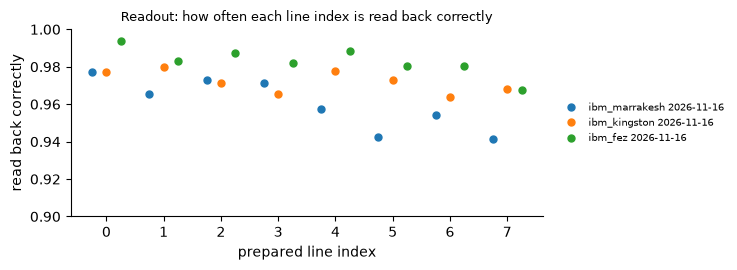

In [6]:
if saved:
    display(plots.table(
        ["job", "shots", "ε", "shots for ≤1% misses", "cutoffs"],
        [(job.label, job.first["shots"], f"{job.measured_profile.epsilon:.3f}",
          job.measured_profile.shots_needed(0.01, job.first["budget"]) or "more than 16384", job.first["cutoffs"])
         for job in saved], "lrrrl"))
    plots.readout_diagonals({job.label: job.measured_profile for job in saved},
                            "Readout: how often each line index is read back correctly")
    plt.show()

## 3. All boards

Each dot is one line of one board: its count divided by its cutoff, so the
black line at 1 is every line's cutoff alike. A winning line (green) at or
above it was found; below it, missed. Losing lines (gray) should stay below
it; one that reaches it (orange x) is flagged and then rejected by the
classical check. Under each group: how many were found, or flagged. The table
counts each kind of board by outcome, and the boards that missed a line or
flagged a losing one are listed in full under it (click to open).

**ibm_marrakesh 2026-11-16**: 48 boards, 2048 shots

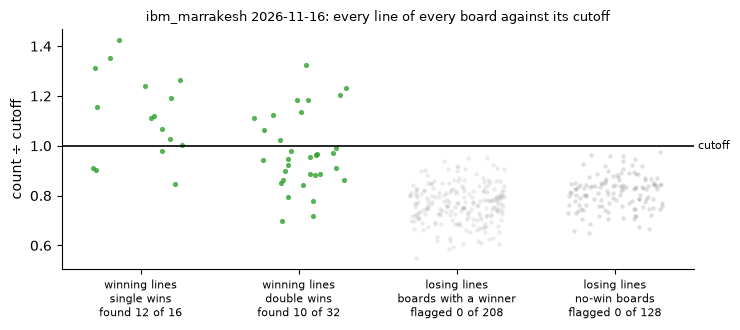

| board | boards | correct | partly missed | missed |
| :--- | ---: | ---: | ---: | ---: |
| single win | 16 | 12 | - | 4 |
| double win | 16 | - | 10 | 6 |
| no win | 16 | 16 | - | - |

<details><summary>The 20 boards that missed a line or flagged a losing one</summary>

| # | board | confirmed | rejected | share on winning lines | outcome |
| ---: | :--- | :--- | :--- | ---: | :--- |
| 4 | X wins the right column and diagonal from top-right (turn 9) | [] | [] | 28.6% | missed |
| 8 | X wins the bottom row and middle column (turn 9) | [2] | [] | 30.7% | partly missed |
| 9 | X wins the left column and diagonal from top-left (turn 9) | [3] | [] | 30.4% | partly missed |
| 17 | X wins the right column (turn 7) | [] | [] | 14.9% | missed |
| 18 | X wins the middle column and diagonal from top-right (turn 9) | [] | [] | 25.8% | missed |
| 23 | X wins the diagonal from top-right (turn 5) | [] | [] | 14.9% | missed |
| 24 | X wins the middle row and left column (turn 9) | [] | [] | 29.3% | missed |
| 25 | O wins the diagonal from top-right (turn 8) | [] | [] | 13.9% | missed |
| 26 | O wins the diagonal from top-left (turn 6) | [] | [] | 12.8% | missed |
| 30 | X wins the top row and right column (turn 9) | [0] | [] | 32.1% | partly missed |
| 33 | X wins the left column and diagonal from top-right (turn 9) | [] | [] | 26.5% | missed |
| 36 | X wins the diagonal from top-left and diagonal from top-right (turn 9) | [] | [] | 26.8% | missed |
| 38 | X wins the middle row and diagonal from top-left (turn 9) | [1] | [] | 29.5% | partly missed |
| 41 | X wins the top row and diagonal from top-left (turn 9) | [0] | [] | 29.6% | partly missed |
| 42 | X wins the bottom row and right column (turn 9) | [2] | [] | 32.5% | partly missed |
| 43 | X wins the top row and left column (turn 9) | [0] | [] | 32.3% | partly missed |
| 44 | X wins the top row and diagonal from top-right (turn 9) | [0] | [] | 31.9% | partly missed |
| 45 | X wins the bottom row and diagonal from top-left (turn 9) | [2] | [] | 31.0% | partly missed |
| 46 | X wins the right column and diagonal from top-left (turn 9) | [] | [] | 28.5% | missed |
| 47 | X wins the top row and middle column (turn 9) | [0] | [] | 30.5% | partly missed |

</details>

**ibm_kingston 2026-11-16**: 282 boards, 2048 shots

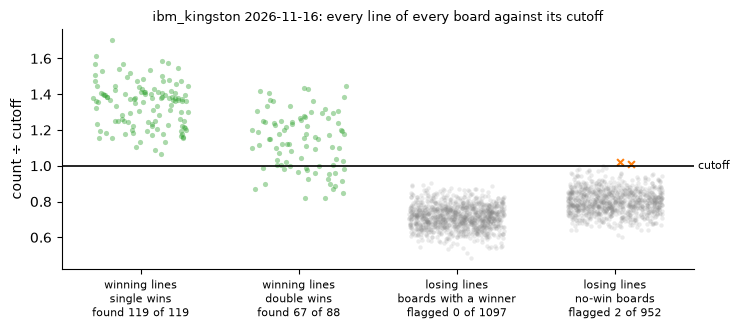

| board | boards | correct | correct, false flag | partly missed |
| :--- | ---: | ---: | ---: | ---: |
| single win | 119 | 119 | - | - |
| double win | 44 | 23 | - | 21 |
| no win | 119 | 117 | 2 | - |

<details><summary>The 23 boards that missed a line or flagged a losing one</summary>

| # | board | confirmed | rejected | share on winning lines | outcome |
| ---: | :--- | :--- | :--- | ---: | :--- |
| 36 | X wins the middle row and left column (turn 9) | [1] | [] | 36.1% | partly missed |
| 40 | X wins the diagonal from top-left and diagonal from top-right (turn 9) | [6] | [] | 31.7% | partly missed |
| 42 | X wins the middle row and right column (turn 9) | [1] | [] | 37.8% | partly missed |
| 49 | X wins the middle column and diagonal from top-right (turn 9) | [4] | [] | 34.6% | partly missed |
| 61 | X wins the bottom row and right column (turn 9) | [2] | [] | 36.3% | partly missed |
| 84 | X wins the right column and diagonal from top-left (turn 9) | [6] | [] | 30.6% | partly missed |
| 93 | X wins the top row and diagonal from top-right (turn 9) | [0] | [] | 35.1% | partly missed |
| 111 | X wins the right column and diagonal from top-left (turn 9) | [6] | [] | 31.5% | partly missed |
| 139 | X wins the left column and diagonal from top-right (turn 9) | [3] | [] | 33.6% | partly missed |
| 140 | X wins the bottom row and right column (turn 9) | [2] | [] | 36.1% | partly missed |
| 146 | X wins the top row and left column (turn 9) | [0] | [] | 36.7% | partly missed |
| 160 | X wins the bottom row and diagonal from top-right (turn 9) | [2] | [] | 36.2% | partly missed |
| 165 | X wins the left column and diagonal from top-right (turn 9) | [3] | [] | 31.1% | partly missed |
| 190 | X wins the top row and left column (turn 9) | [0] | [] | 35.3% | partly missed |
| 191 | X wins the bottom row and diagonal from top-right (turn 9) | [2] | [] | 34.3% | partly missed |
| 219 | X wins the diagonal from top-left and diagonal from top-right (turn 9) | [6] | [] | 31.9% | partly missed |
| 223 | X wins the top row and diagonal from top-right (turn 9) | [0] | [] | 35.4% | partly missed |
| 242 | X wins the top row and diagonal from top-left (turn 9) | [0] | [] | 38.1% | partly missed |
| 243 | X wins the right column and diagonal from top-right (turn 9) | [7] | [] | 33.6% | partly missed |
| 251 | X wins the top row and right column (turn 9) | [0] | [] | 40.0% | partly missed |
| 253 | no winner (O just moved, turn 8) | [] | [5] | - | correct, false flag |
| 271 | no winner (X just moved, turn 9) | [] | [0] | - | correct, false flag |
| 272 | X wins the middle row and right column (turn 9) | [1] | [] | 36.4% | partly missed |

</details>

**ibm_fez 2026-11-16**: 282 boards, 2048 shots

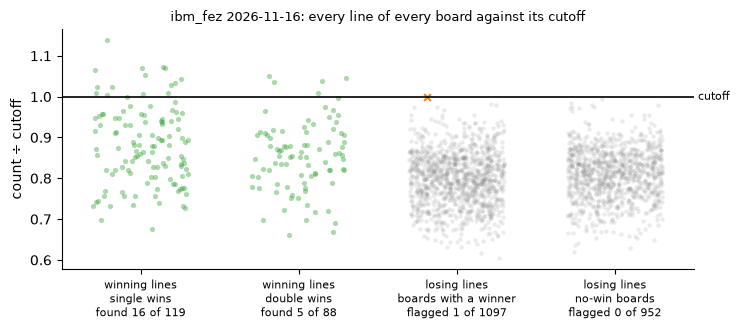

| board | boards | correct | partly missed | missed | missed, false flag |
| :--- | ---: | ---: | ---: | ---: | ---: |
| single win | 119 | 16 | - | 102 | 1 |
| double win | 44 | - | 5 | 39 | - |
| no win | 119 | 119 | - | - | - |

<details><summary>The 147 boards that missed a line or flagged a losing one</summary>

| # | board | confirmed | rejected | share on winning lines | outcome |
| ---: | :--- | :--- | :--- | ---: | :--- |
| 3 | X wins the top row (turn 9) | [] | [] | 13.0% | missed |
| 5 | X wins the middle row (turn 7) | [] | [] | 14.3% | missed |
| 7 | X wins the right column (turn 7) | [] | [] | 12.5% | missed |
| 9 | O wins the middle row (turn 8) | [] | [] | 14.3% | missed |
| 11 | X wins the left column (turn 9) | [] | [] | 14.2% | missed |
| 13 | X wins the diagonal from top-right (turn 9) | [] | [] | 11.8% | missed |
| 14 | O wins the left column (turn 6) | [] | [] | 14.3% | missed |
| 16 | X wins the left column and diagonal from top-left (turn 9) | [] | [] | 27.9% | missed |
| 17 | O wins the middle row (turn 6) | [] | [] | 14.1% | missed |
| 20 | X wins the bottom row (turn 5) | [] | [] | 15.6% | missed |
| 23 | X wins the middle row and diagonal from top-right (turn 9) | [] | [] | 25.8% | missed |
| 26 | X wins the left column and diagonal from top-left (turn 9) | [] | [] | 25.7% | missed |
| 27 | X wins the left column (turn 7) | [] | [] | 13.8% | missed |
| 29 | X wins the top row and middle column (turn 9) | [0] | [] | 28.6% | partly missed |
| 30 | O wins the middle column (turn 6) | [] | [] | 13.3% | missed |
| 31 | O wins the left column (turn 6) | [] | [] | 13.0% | missed |
| 34 | X wins the middle column (turn 7) | [] | [] | 13.9% | missed |
| 36 | X wins the middle row and left column (turn 9) | [] | [] | 26.3% | missed |
| 40 | X wins the diagonal from top-left and diagonal from top-right (turn 9) | [] | [] | 24.5% | missed |
| 41 | O wins the left column (turn 8) | [] | [] | 13.2% | missed |
| 42 | X wins the middle row and right column (turn 9) | [] | [] | 24.5% | missed |
| 44 | X wins the middle column and diagonal from top-left (turn 9) | [] | [] | 25.9% | missed |
| 47 | O wins the middle column (turn 8) | [] | [] | 12.6% | missed |
| 49 | X wins the middle column and diagonal from top-right (turn 9) | [] | [] | 25.0% | missed |
| 52 | X wins the diagonal from top-left (turn 5) | [] | [] | 11.3% | missed |
| 54 | X wins the middle column (turn 7) | [] | [] | 11.1% | missed |
| 56 | O wins the right column (turn 6) | [] | [] | 12.1% | missed |
| 57 | O wins the right column (turn 6) | [] | [] | 13.0% | missed |
| 59 | X wins the middle row (turn 9) | [] | [] | 11.6% | missed |
| 61 | X wins the bottom row and right column (turn 9) | [] | [] | 25.9% | missed |
| 63 | O wins the diagonal from top-right (turn 6) | [] | [] | 12.6% | missed |
| 64 | X wins the bottom row and left column (turn 9) | [] | [] | 27.9% | missed |
| 65 | X wins the diagonal from top-left (turn 7) | [] | [] | 11.7% | missed |
| 66 | O wins the right column (turn 8) | [] | [] | 12.6% | missed |
| 67 | X wins the middle column (turn 9) | [] | [] | 13.1% | missed |
| 69 | X wins the bottom row (turn 9) | [] | [] | 14.8% | missed |
| 71 | X wins the right column (turn 5) | [] | [] | 12.1% | missed |
| 75 | X wins the middle row (turn 9) | [] | [] | 13.5% | missed |
| 78 | O wins the right column (turn 6) | [] | [] | 11.8% | missed |
| 79 | O wins the left column (turn 8) | [] | [] | 13.2% | missed |
| 80 | O wins the middle column (turn 6) | [] | [] | 11.5% | missed |
| 81 | X wins the diagonal from top-left (turn 9) | [] | [] | 12.7% | missed |
| 84 | X wins the right column and diagonal from top-left (turn 9) | [] | [] | 24.4% | missed |
| 86 | O wins the middle row (turn 6) | [] | [] | 14.2% | missed |
| 91 | O wins the middle row (turn 6) | [] | [] | 14.5% | missed |
| 92 | X wins the middle column and diagonal from top-right (turn 9) | [] | [] | 26.7% | missed |
| 93 | X wins the top row and diagonal from top-right (turn 9) | [] | [] | 27.7% | missed |
| 94 | O wins the middle column (turn 8) | [] | [] | 12.8% | missed |
| 95 | O wins the left column (turn 8) | [] | [] | 13.7% | missed |
| 99 | X wins the diagonal from top-right (turn 7) | [] | [] | 12.3% | missed |
| 101 | X wins the diagonal from top-left (turn 7) | [] | [] | 12.2% | missed |
| 102 | O wins the diagonal from top-left (turn 6) | [] | [] | 11.7% | missed |
| 105 | O wins the bottom row (turn 6) | [] | [] | 16.2% | missed |
| 110 | X wins the middle row and diagonal from top-left (turn 9) | [] | [] | 25.9% | missed |
| 111 | X wins the right column and diagonal from top-left (turn 9) | [] | [] | 24.5% | missed |
| 113 | X wins the top row (turn 7) | [] | [6] | 13.8% | missed, false flag |
| 114 | X wins the bottom row (turn 7) | [] | [] | 16.2% | missed |
| 115 | X wins the right column and diagonal from top-right (turn 9) | [] | [] | 24.7% | missed |
| 116 | O wins the bottom row (turn 6) | [] | [] | 15.3% | missed |
| 117 | X wins the middle row and diagonal from top-right (turn 9) | [] | [] | 27.3% | missed |
| 118 | X wins the middle column (turn 5) | [] | [] | 12.8% | missed |
| 124 | X wins the left column (turn 9) | [] | [] | 12.1% | missed |
| 125 | X wins the top row and middle column (turn 9) | [0] | [] | 27.8% | partly missed |
| 126 | X wins the left column (turn 7) | [] | [] | 12.5% | missed |
| 128 | O wins the middle row (turn 8) | [] | [] | 14.6% | missed |
| 132 | O wins the diagonal from top-left (turn 8) | [] | [] | 13.1% | missed |
| 133 | X wins the middle row (turn 9) | [] | [] | 13.7% | missed |
| 134 | X wins the bottom row and diagonal from top-left (turn 9) | [] | [] | 27.9% | missed |
| 135 | X wins the middle row and diagonal from top-left (turn 9) | [] | [] | 25.7% | missed |
| 137 | X wins the middle column (turn 5) | [] | [] | 13.6% | missed |
| 138 | O wins the diagonal from top-right (turn 8) | [] | [] | 14.6% | missed |
| 139 | X wins the left column and diagonal from top-right (turn 9) | [] | [] | 25.0% | missed |
| 140 | X wins the bottom row and right column (turn 9) | [] | [] | 27.1% | missed |
| 142 | X wins the top row and diagonal from top-left (turn 9) | [] | [] | 24.6% | missed |
| 144 | X wins the diagonal from top-right (turn 5) | [] | [] | 12.9% | missed |
| 146 | X wins the top row and left column (turn 9) | [] | [] | 26.7% | missed |
| 148 | O wins the diagonal from top-right (turn 8) | [] | [] | 13.2% | missed |
| 150 | O wins the middle column (turn 8) | [] | [] | 12.7% | missed |
| 151 | O wins the right column (turn 6) | [] | [] | 12.0% | missed |
| 154 | X wins the left column (turn 5) | [] | [] | 13.3% | missed |
| 157 | O wins the diagonal from top-left (turn 8) | [] | [] | 13.0% | missed |
| 158 | O wins the diagonal from top-right (turn 6) | [] | [] | 12.4% | missed |
| 159 | X wins the top row (turn 9) | [] | [] | 14.2% | missed |
| 160 | X wins the bottom row and diagonal from top-right (turn 9) | [] | [] | 25.2% | missed |
| 161 | X wins the top row and right column (turn 9) | [0] | [] | 28.3% | partly missed |
| 164 | X wins the right column (turn 5) | [] | [] | 12.4% | missed |
| 165 | X wins the left column and diagonal from top-right (turn 9) | [] | [] | 27.7% | missed |
| 167 | O wins the diagonal from top-right (turn 8) | [] | [] | 11.7% | missed |
| 168 | O wins the diagonal from top-left (turn 6) | [] | [] | 12.0% | missed |
| 172 | X wins the middle row and left column (turn 9) | [] | [] | 26.2% | missed |
| 173 | X wins the diagonal from top-right (turn 9) | [] | [] | 12.9% | missed |
| 174 | X wins the right column (turn 5) | [] | [] | 12.0% | missed |
| 177 | O wins the middle row (turn 6) | [] | [] | 14.4% | missed |
| 179 | O wins the left column (turn 8) | [] | [] | 14.7% | missed |
| 180 | X wins the middle column and diagonal from top-left (turn 9) | [] | [] | 25.7% | missed |
| 182 | X wins the diagonal from top-left (turn 7) | [] | [] | 12.9% | missed |
| 183 | O wins the diagonal from top-left (turn 6) | [] | [] | 13.2% | missed |
| 186 | O wins the right column (turn 6) | [] | [] | 12.3% | missed |
| 188 | X wins the middle row (turn 9) | [] | [] | 14.4% | missed |
| 190 | X wins the top row and left column (turn 9) | [0] | [] | 27.3% | partly missed |
| 191 | X wins the bottom row and diagonal from top-right (turn 9) | [] | [] | 27.8% | missed |
| 192 | X wins the middle column (turn 7) | [] | [] | 12.5% | missed |
| 193 | O wins the bottom row (turn 8) | [] | [] | 15.0% | missed |
| 196 | X wins the diagonal from top-left (turn 5) | [] | [] | 12.5% | missed |
| 197 | X wins the diagonal from top-right (turn 9) | [] | [] | 11.2% | missed |
| 198 | O wins the middle column (turn 8) | [] | [] | 12.1% | missed |
| 202 | X wins the right column (turn 9) | [] | [] | 12.6% | missed |
| 203 | O wins the bottom row (turn 8) | [] | [] | 14.4% | missed |
| 207 | X wins the diagonal from top-left (turn 7) | [] | [] | 11.4% | missed |
| 208 | O wins the right column (turn 6) | [] | [] | 12.3% | missed |
| 210 | O wins the bottom row (turn 8) | [] | [] | 14.8% | missed |
| 212 | O wins the diagonal from top-left (turn 6) | [] | [] | 13.9% | missed |
| 213 | X wins the left column (turn 5) | [] | [] | 13.5% | missed |
| 214 | X wins the middle row (turn 7) | [] | [] | 14.0% | missed |
| 216 | O wins the left column (turn 8) | [] | [] | 12.9% | missed |
| 217 | O wins the middle row (turn 6) | [] | [] | 13.8% | missed |
| 219 | X wins the diagonal from top-left and diagonal from top-right (turn 9) | [] | [] | 25.9% | missed |
| 220 | X wins the bottom row and left column (turn 9) | [] | [] | 26.8% | missed |
| 223 | X wins the top row and diagonal from top-right (turn 9) | [] | [] | 25.9% | missed |
| 224 | X wins the bottom row and middle column (turn 9) | [] | [] | 26.9% | missed |
| 225 | X wins the left column (turn 9) | [] | [] | 13.6% | missed |
| 226 | O wins the diagonal from top-left (turn 6) | [] | [] | 12.0% | missed |
| 230 | X wins the right column (turn 5) | [] | [] | 13.0% | missed |
| 231 | X wins the bottom row (turn 7) | [] | [] | 15.7% | missed |
| 233 | O wins the middle column (turn 8) | [] | [] | 12.5% | missed |
| 235 | X wins the top row (turn 5) | [] | [] | 14.1% | missed |
| 236 | X wins the middle column (turn 5) | [] | [] | 12.5% | missed |
| 237 | X wins the bottom row and diagonal from top-left (turn 9) | [] | [] | 26.8% | missed |
| 242 | X wins the top row and diagonal from top-left (turn 9) | [] | [] | 26.3% | missed |
| 243 | X wins the right column and diagonal from top-right (turn 9) | [] | [] | 22.1% | missed |
| 244 | X wins the middle row and middle column (turn 9) | [] | [] | 27.4% | missed |
| 245 | X wins the bottom row and middle column (turn 9) | [] | [] | 27.6% | missed |
| 248 | X wins the diagonal from top-left (turn 5) | [] | [] | 13.2% | missed |
| 249 | X wins the diagonal from top-right (turn 5) | [] | [] | 13.4% | missed |
| 250 | O wins the bottom row (turn 6) | [] | [] | 15.9% | missed |
| 251 | X wins the top row and right column (turn 9) | [0] | [] | 27.5% | partly missed |
| 254 | O wins the left column (turn 8) | [] | [] | 13.5% | missed |
| 255 | X wins the middle row and middle column (turn 9) | [] | [] | 26.1% | missed |
| 258 | O wins the top row (turn 6) | [] | [] | 14.3% | missed |
| 262 | X wins the diagonal from top-right (turn 7) | [] | [] | 13.4% | missed |
| 263 | X wins the bottom row (turn 9) | [] | [] | 14.5% | missed |
| 266 | O wins the diagonal from top-right (turn 8) | [] | [] | 14.4% | missed |
| 272 | X wins the middle row and right column (turn 9) | [] | [] | 26.2% | missed |
| 275 | O wins the right column (turn 8) | [] | [] | 12.2% | missed |
| 277 | O wins the diagonal from top-right (turn 8) | [] | [] | 12.7% | missed |
| 278 | X wins the right column (turn 7) | [] | [] | 13.6% | missed |
| 282 | X wins the middle column (turn 9) | [] | [] | 11.1% | missed |

</details>

In [7]:
for job in saved:
    display(plots.markdown(f"**{job.label}**: {len(job.detections)} boards, {job.first['shots']} shots"))
    plots.cutoff_margins(job.detections, f"{job.label}: every line of every board against its cutoff")
    plt.show()
    tally = Counter((r["label"], outcome(r)) for r in job.detections)
    seen = [o for o in OUTCOMES if any(o == key[1] for key in tally)]
    display(plots.table(
        ["board", "boards", *seen],
        [(label.replace("_", " "), sum(tally[label, o] for o in seen), *(tally[label, o] or "-" for o in seen))
         for label in ("single_win", "double_win", "no_win") if any(tally[label, o] for o in seen)],
        "l" + "r" * (len(seen) + 1)))
    failing = [(n, r) for n, r in enumerate(job.detections, start=1) if outcome(r) != "correct"]
    if failing:
        listing = plots.table(
            ["#", "board", "confirmed", "rejected", "share on winning lines", "outcome"],
            [(n, describe(r), r["lines"], r["rejected"],
              f"{sum(r['counts'][i] for i in r['true_lines']) / r['shots']:.1%}" if r["true_lines"] else "-",
              outcome(r)) for n, r in failing], "rlllrl").data
        display(plots.markdown(f"<details><summary>The {len(failing)} boards that missed a line or flagged a "
                               f"losing one</summary>\n\n{listing}\n\n</details>"))

### Browse every board

Running this notebook (in Jupyter or VS Code) shows a browser here: pick a
job, a kind of board and an outcome, then step through the boards with the
slider or the buttons, each drawn as in the examples above. Static viewers such as GitHub show a placeholder.

In [8]:
if entries:
    display(plots.BoardBrowser(entries))

[Board browser: run this notebook in Jupyter or VS Code to step through every board.]

## 4. Results by kind of board

- **Win found:** at least one winning line confirmed; **all lines** counts
  double wins only when both lines were found.
- **False flag:** a losing line reached its cutoff. The classical check
  rejects it, so it costs one extra check but never produces a wrong winner.
  The budget allows about 0.2 per board; clearly more on no-win boards means
  the noise is not spreading evenly over the losing lines as the model assumes.
- **Checks per board** counts classical line checks; checking every line would
  be 8. That is not a speedup: every shot evaluates all 8 lines (Part 1,
  section 10).
- **By line index:** the share of each winning line found, over every board
  where it was a winning line. A line found clearly less often than the others
  points to the qubits, or the bit of the line index, that lose the most
  signal (section 2).

**ibm_marrakesh 2026-11-16**

| board | boards | win found | 95% interval | all lines | false flags | checks per board |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| no win | 16 | - | - | - | 0 | 0.00 |
| single win | 16 | 12/16 | 51%–90% | 12/16 | 0 | 0.75 |
| double win | 16 | 10/16 | 39%–82% | 0/16 | 0 | 0.62 |

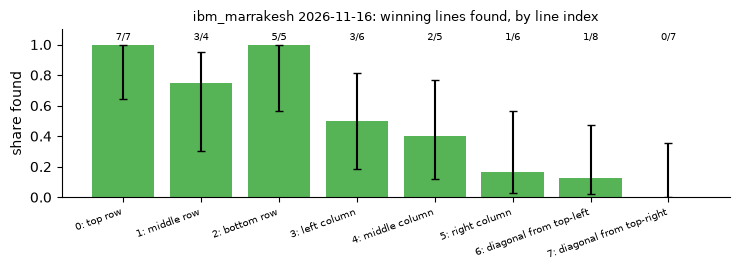

**ibm_kingston 2026-11-16**

| board | boards | win found | 95% interval | all lines | false flags | checks per board |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| no win | 119 | - | - | - | 2 | 0.02 |
| single win | 119 | 119/119 | 97%–100% | 119/119 | 0 | 1.00 |
| double win | 44 | 44/44 | 92%–100% | 23/44 | 0 | 1.52 |

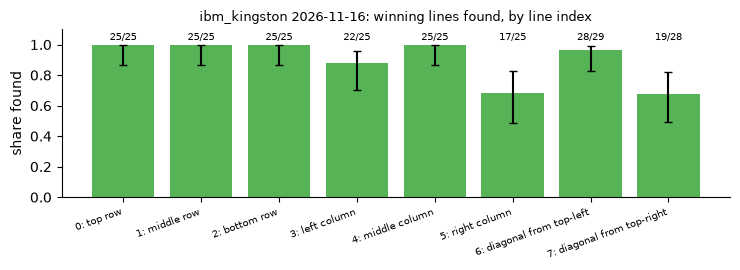

**ibm_fez 2026-11-16**

| board | boards | win found | 95% interval | all lines | false flags | checks per board |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| no win | 119 | - | - | - | 0 | 0.00 |
| single win | 119 | 16/119 | 8%–21% | 16/119 | 1 | 0.14 |
| double win | 44 | 5/44 | 5%–24% | 0/44 | 0 | 0.11 |

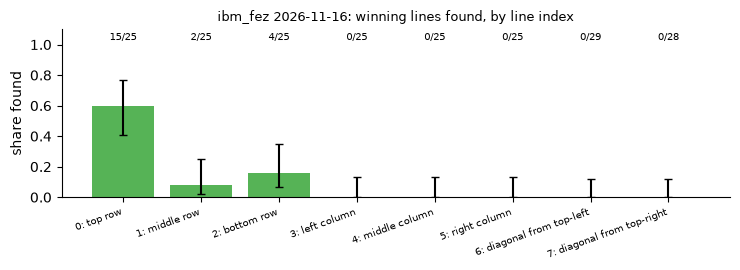

No reported line was ever a wrong winner.


In [9]:
for job in saved:
    rows = []
    for row in summarize(job.detections):
        win = row.label != "no_win"
        low, high = row.found_interval
        rows.append((row.label.replace("_", " "), row.boards, f"{row.wins_found}/{row.boards}" if win else "-",
                     f"{low:.0%}–{high:.0%}" if win else "-", f"{row.all_lines_found}/{row.boards}" if win else "-",
                     row.false_flags, f"{row.checks / row.boards:.2f}"))
    display(plots.markdown(f"**{job.label}**"))
    display(plots.table(["board", "boards", "win found", "95% interval", "all lines", "false flags", "checks per board"],
                        rows, "lrrrrrr"))
    with_winner = [r for r in job.detections if r["true_lines"]]
    if with_winner:
        plots.found_by_line([sum(i in r["lines"] for r in with_winner) for i in range(8)],
                            [sum(i in r["true_lines"] for r in with_winner) for i in range(8)],
                            f"{job.label}: winning lines found, by line index")
        plt.show()
if saved:
    wrong = wrong_winners([d for job in saved for d in job.detections])
    assert not wrong, f"{len(wrong)} reported line(s) were not real wins"
    print("No reported line was ever a wrong winner.")

## 5. Measured vs predicted

For each board with a winner: the share of shots on its winning line(s)
measured in the job (up), against the share two predictions of the same
simple model give (across), one dot per board and prediction. One uses the
device's published calibration data, saved with the job when it was
submitted, for the same compiled circuit (left out for providers that publish
no gate errors). The other uses the noise profile measured in the job. On the
dashed diagonal a prediction is exact; below it the device did worse than
predicted. The table gives each prediction's average gap and its spread.

**ibm_marrakesh 2026-11-16**

| prediction | boards | mean measured − predicted | RMS difference |
| :--- | ---: | ---: | ---: |
| measured profile | 32 | -0.010 | 0.020 |
| published data | 32 | -0.181 | 0.183 |

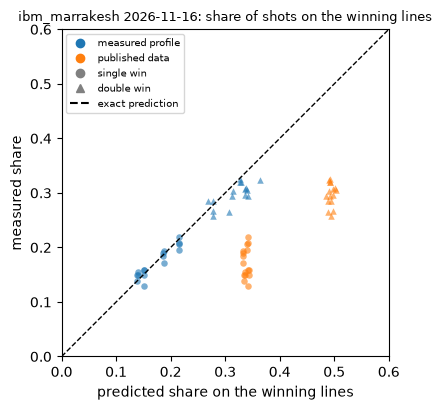

**ibm_kingston 2026-11-16**

| prediction | boards | mean measured − predicted | RMS difference |
| :--- | ---: | ---: | ---: |
| measured profile | 163 | -0.009 | 0.018 |
| published data | 163 | -0.154 | 0.156 |

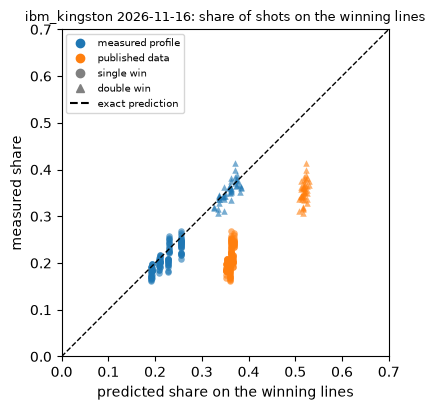

**ibm_fez 2026-11-16**

| prediction | boards | mean measured − predicted | RMS difference |
| :--- | ---: | ---: | ---: |
| measured profile | 163 | -0.005 | 0.012 |
| published data | 163 | -0.218 | 0.219 |

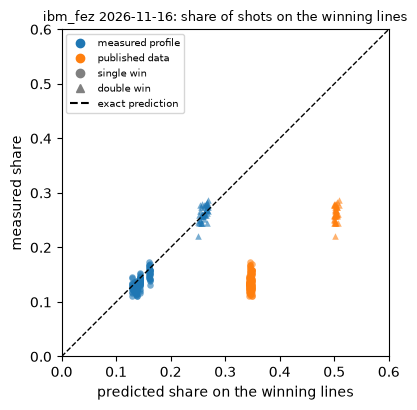

In [10]:
for job in saved:
    wins = [r for r in job.detections if r["true_lines"]]
    if not wins:
        continue
    models = {"measured profile": job.measured_profile}
    if job.published_profile is not None:
        models["published data"] = job.published_profile
    points = {name: [(sum(profile.predicted_for(r["true_lines"])[i] for i in r["true_lines"]),
                      sum(r["counts"][i] for i in r["true_lines"]) / r["shots"], len(r["true_lines"]) == 2)
                     for r in wins] for name, profile in models.items()}
    gaps = {name: np.array([measured - predicted for predicted, measured, _ in rows]) for name, rows in points.items()}
    display(plots.markdown(f"**{job.label}**"))
    display(plots.table(["prediction", "boards", "mean measured − predicted", "RMS difference"],
                        [(name, len(g), f"{g.mean():+.3f}", f"{np.sqrt((g ** 2).mean()):.3f}")
                         for name, g in gaps.items()], "lrrr"))
    plots.predicted_vs_measured(points, f"{job.label}: share of shots on the winning lines")
    plt.show()

**What to notice:** where the published-data dots sit well below the diagonal
(a negative mean gap), the device is noisier than its published calibration
says, as Part 2 found in simulation. Both predictions use the same model; the
measured one also gives each bit of the line index its own signal factor, so
its dots should straddle the diagonal. Boards far from it show where that
model is too simple.

## 6. Summary of findings

**Findings**

- **No wrong winners.** Every line the quantum search flags is verified on the
  board, so noise can cause a missed win or an extra check but never a false
  result; section 4 checks this on every saved board.
- **Noise measured in the same job.** Each job fits its own readout matrix, ε
  and per-bit signal from its calibration circuits, so the cutoffs reflect the
  device on the day rather than a published snapshot, which Part 2 showed
  understates the noise.
- **A 12-qubit circuit.** Reducing the original circuit from 22 qubits to 12
  (Part 1) is what leaves a usable signal.

**Limitations**

- **Noise is close to this circuit's limit.** Section 2 gives each job's
  measured ε and the shots needed for at most 1% misses; where that far
  exceeds the shots used, wins are missed. The limit is the hardware's, not
  the detector's: the same rule finds every win on a perfect simulator.
- **The noise model is simple:** one ε plus a factor per bit. Section 5 shows
  where it deviates.
- **Error suppression is set per job.** Section 1 lists each job's. A job with
  it off (no dynamical decoupling or gate twirling) measures the raw device, so
  its numbers are not directly comparable with a job that had it on.

## Appendix: sending a job

Requires an IBM Quantum account and uses plan time; only IBM devices are
supported. Put `QISKIT_IBM_TOKEN=...` in the repo's `.env` (see
`.env.example`), fill in the parameters below (`SUBMIT_TO`, `N_BOARDS`,
`SHOTS` and `ERROR_SUPPRESSION` are required; the rest may stay `None`), set
`RUN_HARDWARE = True` and run the notebook once, then set it back to `False`
and re-run it to see the new job above. The same batch can be sent from a
terminal with
`python scripts/collect.py --backend <device> --n <boards> --shots auto --tag <name>`,
which runs without error suppression unless given `--error-suppression`.

In [11]:
from qttt.backends import ERROR_SUPPRESSION_OPTIONS, get_backend
from qttt.experiments import choose_shots, collect, default_tag, sample_boards
from qttt.noise import CALIBRATION_CIRCUITS

RUN_HARDWARE = False  # True submits one job to SUBMIT_TO (uses your plan's time)
SUBMIT_TO = None  # required: an IBM device, e.g. "ibm_kingston"
N_BOARDS = None  # required: boards in the job, balanced over label, winning line, last mover and turn
SHOTS = None  # required: shots per board, or "auto": a short calibration job first picks them for at most 1% misses
ERROR_SUPPRESSION = None  # required: True for dynamical decoupling (XY4) and gate twirling, False for none (better so far)
MAX_SHOTS = None  # with SHOTS = "auto", the most it may pick; None: the package default
SEED = None  # for the boards drawn and the compiling; None: a new draw every run
TAG = None  # a name to find the batch by in results/; None: a timestamp

if RUN_HARDWARE:
    missing = [name for name, value in (("SUBMIT_TO", SUBMIT_TO), ("N_BOARDS", N_BOARDS), ("SHOTS", SHOTS),
                                        ("ERROR_SUPPRESSION", ERROR_SUPPRESSION))
               if value is None]
    if missing:
        raise ValueError(f"set {', '.join(missing)} before submitting")
    tag = TAG or default_tag()  # the calibration job and the batch share it
    boards = sample_boards(N_BOARDS, seed=SEED)
    device = get_backend(SUBMIT_TO, seed=SEED, transpile_seeds=5,
                         sampler_options=ERROR_SUPPRESSION_OPTIONS if ERROR_SUPPRESSION else None)
    shots = SHOTS
    if shots == "auto":
        limit = {} if MAX_SHOTS is None else {"max_shots": MAX_SHOTS}
        shots, _ = choose_shots(device, store=STORE, tag=tag, **limit)
        print(f"A calibration job on {SUBMIT_TO} chose {shots} shots per board.")
    print(f"Submitting {len(boards)} boards + {CALIBRATION_CIRCUITS} calibration circuits to {SUBMIT_TO}"
          f" ({shots} shots each)...")
    collect(boards, device, shots=shots, store=STORE, tag=tag)
    print("Done; saved to", STORE.runs_file)

---

[← Part 2: Noise](02_noise.ipynb) · [Part 1: How it works](01_how_it_works.ipynb) · [README](../README.md)